# 🏫 컴퓨터는 어떻게 스스로 답을 찾을까?
## 회귀(Regression)로 배우는 AI의 학습 원리

| 단계 | 내용 | 활동 |
|---|---|---|
| 도입 | 회귀란 무엇인가 | 질문·토의 |
| 전개 1 | 모델과 손실 함수 | 개념 설명 |
| 전개 2 | 실습 ① 무작정 w 찾기 | 코랩 실습 |
| 전개 3 | 실습 ② 경사하강법 | 코랩 실습 |
| 전개 4 | 실습 ③ 절편 추가 (파라미터 2개) | 코랩 실습 |
| 정리 | 실습 ④ 소리의 속도 예측 | 개별 과제 |

> 각 셀을 위에서부터 순서대로 실행하세요. (셀 왼쪽의 ▶ 버튼 또는 `Shift + Enter`)

---
## 1️⃣ 도입 — 회귀(Regression)란?

**퀴즈!** X가 [1, 2, 3]일 때 Y가 [2, 4, 6]이에요. 그럼 **X가 4일 때 Y는?**

...맞아요, **8**이죠. 그런데 여러분은 어떻게 8이라는 걸 알았나요?

머릿속에서 "Y는 X의 2배구나", 즉 **y = 2x라는 규칙(함수)** 을 찾아낸 거예요.

- 이렇게 **데이터를 보고 x와 y 사이의 관계(함수)를 찾아내는 것** → **회귀(Regression)**
- 그 관계를 **직선(1차식)** 으로 찾는 것 → **선형 회귀(Linear Regression)**

여러분은 직관으로 한 번에 찾았지만, 컴퓨터는 직관이 없어요.

> 💡 **오늘의 핵심 질문: 컴퓨터는 어떻게 스스로 규칙을 찾는가?**

---
## 2️⃣ 모델과 손실 함수(Loss Function)

컴퓨터에게는 먼저 **모델**이라는 틀을 줍니다.

$$\hat{y} = w \cdot x$$

"여기서 **w**라는 숫자만 네가 찾아봐!" — 이 w를 **가중치(weight)** 또는 **파라미터**라고 부릅니다.

어떤 w가 좋은지 판단할 **채점 기준**이 바로 **손실 함수(Loss Function)** 입니다.
예측값 $\hat{y}$ 과 정답 $y$ 의 오차를 **제곱해서 모두 더한 것**:

$$E(w) = \sum_{n} (y_n - \hat{y}_n)^2 = \sum_n (y_n - w \cdot x_n)^2$$

**왜 제곱?** 오차가 +2든 −2든 '틀린 정도'는 같으니 부호를 없애고, 크게 틀릴수록 더 큰 벌점을 주기 위해서예요.

> 💡 **학습 = 손실(loss)을 가장 작게 만드는 w를 찾는 게임!**

---
## 3️⃣ 실습 ① — 무작정 w를 바꿔보기 (Brute Force)

가장 단순한 방법부터! w를 0부터 시작해서 **무작정 0.3씩 키워 가면서** 매번 손실을 계산해 봅시다.

Epoch 0 	w = 0.00 	loss = 56.00
Epoch 1 	w = 0.30 	loss = 40.46
Epoch 2 	w = 0.60 	loss = 27.44
Epoch 3 	w = 0.90 	loss = 16.94
Epoch 4 	w = 1.20 	loss = 8.96
Epoch 5 	w = 1.50 	loss = 3.50
Epoch 6 	w = 1.80 	loss = 0.56
Epoch 7 	w = 2.10 	loss = 0.14
Epoch 8 	w = 2.40 	loss = 2.24
Epoch 9 	w = 2.70 	loss = 6.86
Epoch 10 	w = 3.00 	loss = 14.00
Epoch 11 	w = 3.30 	loss = 23.66
Epoch 12 	w = 3.60 	loss = 35.84
Epoch 13 	w = 3.90 	loss = 50.54
Epoch 14 	w = 4.20 	loss = 67.76
Epoch 15 	w = 4.50 	loss = 87.50
Epoch 16 	w = 4.80 	loss = 109.76
Epoch 17 	w = 5.10 	loss = 134.54
Epoch 18 	w = 5.40 	loss = 161.84
Epoch 19 	w = 5.70 	loss = 191.66


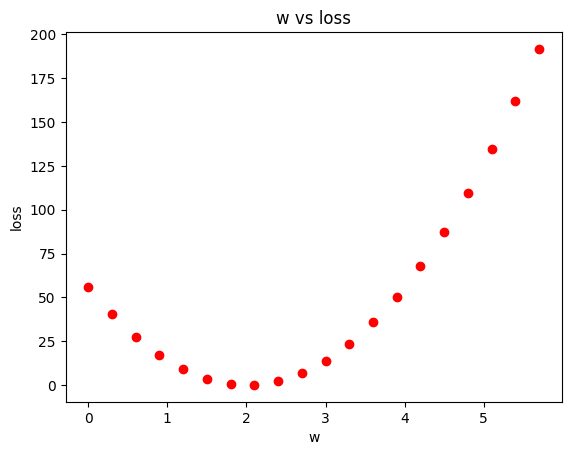

In [ ]:
import matplotlib.pyplot as plt

# 데이터: 정답 규칙은 y = 2x
x_data = [1.0, 2.0, 3.0]
y_data = [2.0, 4.0, 6.0]

# 모델: y = w * x
def predict(w, x):
    return x * w

# 오차의 제곱
def errorSquared(y, y_pred):
    return (y - y_pred) * (y - y_pred)

# 손실 함수: 오차 제곱의 합
def loss(errors):
    return sum(errors)

# w를 무작정 0.3씩 증가시키며 손실 관찰
w = 0.00  # 초기 가중치
for epoch in range(20):
    error = []
    for x, y in zip(x_data, y_data):
        y_pred = predict(w, x)
        error.append(errorSquared(y, y_pred))
    l = loss(error)
    print("Epoch", epoch, "\tw =", '%.2f' % w, "\tloss =", '%.2f' % l)
    plt.scatter(w, l, color='r')
    w = w + 0.3  # 무작정 0.3씩 증가

plt.xlabel('w'); plt.ylabel('loss'); plt.title('w vs loss')
plt.show()

### 🤔 결과 해석

그래프가 **U자(밥그릇) 모양**이죠? 손실이 가장 낮았던 건 **w = 2.40일 때**였어요.
정답은 w = 2인데 왜 2.40에서 멈췄을까요? → 0.3씩 뛰다 보니 **정답 2를 그냥 지나쳐 버린** 거예요.
그렇다고 0.001씩 움직이면 시간이 너무 오래 걸리겠죠.

> ❓ **'지금 내가 정답보다 큰지 작은지, 얼마나 움직여야 하는지'를 똑똑하게 알 수는 없을까?**

---
## 4️⃣ 실습 ② — 경사하강법(Gradient Descent)

U자 그래프를 **산골짜기**라고 상상해 보세요. 안개 속에서 가장 낮은 곳을 찾아 내려가야 해요.
멀리는 안 보이지만 **발밑의 경사(기울기)** 는 느낄 수 있죠.

- 경사가 오른쪽으로 내려가면 → 오른쪽으로 이동
- 경사가 왼쪽으로 내려가면 → 왼쪽으로 이동
- 가파르면 → 성큼성큼, 완만하면 → 조금씩

수식으로는 딱 한 줄:

$$w \leftarrow w - \epsilon \cdot \nabla_w E(w)$$

- **기울기(gradient)** $\nabla_w E$ : 어느 **방향**으로 갈지
- **학습률(learning rate)** $\epsilon$ : **얼마나 멀리** 움직일지

손실 함수를 미분하면 $\nabla_w E = -2 x_n (y_n - x_n w)$.
미분 계산은 지금 몰라도 괜찮아요. 핵심은 **'기울기의 반대 방향으로 조금씩 내려간다'** 입니다.

Epoch 0 	w = 0.28 	loss = 56.00
Epoch 1 	w = 0.52 	loss = 41.42
Epoch 2 	w = 0.73 	loss = 30.63
Epoch 3 	w = 0.91 	loss = 22.66
Epoch 4 	w = 1.06 	loss = 16.76
Epoch 5 	w = 1.19 	loss = 12.39
Epoch 6 	w = 1.30 	loss = 9.17
Epoch 7 	w = 1.40 	loss = 6.78
Epoch 8 	w = 1.49 	loss = 5.01
Epoch 9 	w = 1.56 	loss = 3.71
Epoch 10 	w = 1.62 	loss = 2.74
Epoch 11 	w = 1.67 	loss = 2.03
Epoch 12 	w = 1.72 	loss = 1.50
Epoch 13 	w = 1.76 	loss = 1.11
Epoch 14 	w = 1.79 	loss = 0.82
Epoch 15 	w = 1.82 	loss = 0.61
Epoch 16 	w = 1.85 	loss = 0.45
Epoch 17 	w = 1.87 	loss = 0.33
Epoch 18 	w = 1.89 	loss = 0.25
Epoch 19 	w = 1.90 	loss = 0.18
Epoch 20 	w = 1.92 	loss = 0.13
Epoch 21 	w = 1.93 	loss = 0.10
Epoch 22 	w = 1.94 	loss = 0.07
Epoch 23 	w = 1.95 	loss = 0.05
Epoch 24 	w = 1.95 	loss = 0.04
Epoch 25 	w = 1.96 	loss = 0.03
Epoch 26 	w = 1.97 	loss = 0.02
Epoch 27 	w = 1.97 	loss = 0.02
Epoch 28 	w = 1.97 	loss = 0.01
Epoch 29 	w = 1.98 	loss = 0.01
Epoch 30 	w = 1.98 	loss = 0.01
Epoch 31 	w 

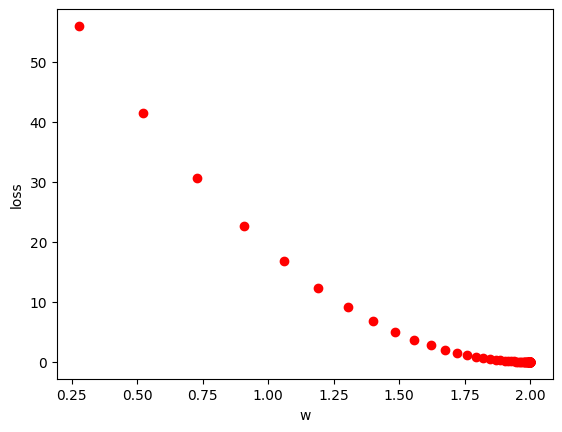

In [ ]:
# 손실 함수의 기울기(gradient)
def gradient(x, y):
    return -2 * x * (y - x * w)

# 학습
w = 0.00               # 초기 가중치
N = 100                 # 학습 회수 20일 때와 100일 때 비교
learning_rate = 0.005  # 학습률 ε
for epoch in range(N):
    error = []    # 오차의 제곱 저장할 배열
    grad = []     # 손실 함수의 기울기 저장할 배열
    for x, y in zip(x_data, y_data):
        y_pred = predict(w, x)
        error.append(errorSquared(y, y_pred))
        grad.append(gradient(x, y))
    l = loss(error)   # 손실 함수: 오차 제곱의 합
    w = w - learning_rate * sum(grad)   # w ← w - ε∇E(w)
    print("Epoch", epoch, "\tw =", '%.2f' % w, "\tloss =", '%.2f' % l)
    plt.scatter(w, l, color='r')

plt.xlabel('w'); plt.ylabel('loss')
plt.show()

### 학습된 모델 테스트

아무도 '정답은 2야'라고 알려주지 않았는데 **컴퓨터가 오차를 줄이는 방향으로 스스로 찾아간 것**입니다.

In [ ]:
print("Predicted value (after training)", "When x=4, y will be :", predict(w, 4)) #  8을 맞힐 수 있나?
print("Predicted value (after training)", "When x=6, y will be :", predict(w, 6)) # 12를 맞힐 수 있나?

Predicted value (after training) When x=4, y will be : 7.999997746097573
Predicted value (after training) When x=6, y will be : 11.999996619146359


> 🧪 **실험해 보기**
> 1. 학습 셀에서 `range(20)` → `range(100)`으로 바꿔 보세요. **더 많이 학습할수록 더 정확한 답**이 나옵니다.
> 2. `learning_rate`를 `0.005` → `0.1`로 바꿔 보세요. w가 **발산**해요. 보폭이 너무 크면 골짜기를 계속 건너뛰어 버립니다!

---
## 5️⃣ 실습 ③ — 절편 추가: 파라미터가 2개라면?

세상 데이터가 다 원점을 지나진 않으니 **절편**을 추가해 모델을 확장합니다:

$$\hat{y} = w_0 + w_1 x$$

이제 파라미터가 **$w_0$, $w_1$ 두 개**! 각 파라미터의 기울기를 따로 구해 **둘 다 동시에** 내려가면 됩니다.

$$\nabla_{w_0} E = -2(y_n - (w_0 + x_n w_1)), \quad \nabla_{w_1} E = -2(y_n - (w_0 + x_n w_1)) \cdot x_n$$

> 💡 실제 딥러닝 모델은 파라미터가 **수십억 개**지만 원리는 완전히 동일해요!

In [ ]:
# 모델: y = w0 + w1 * x
def predict2(w, x):
    return w[0] + w[1] * x

# 학습
w = [0.00, 0.00]      # 초기 가중치 [w0, w1]
epochs = 200
learning_rate = 0.01

for epoch in range(epochs):
    error = []
    grad_w0 = []
    grad_w1 = []
    for x, y in zip(x_data, y_data):
        y_pred = predict2(w, x)
        error.append(errorSquared(y, y_pred))
        grad_w0.append(-2 * (y - (w[0] + x * w[1])))
        grad_w1.append(-2 * (y - (w[0] + x * w[1])) * x)
    l = loss(error)
    w[0] = w[0] - learning_rate * sum(grad_w0)
    w[1] = w[1] - learning_rate * sum(grad_w1)
    print("Epoch", epoch, "\tw_0 =", '%.2f' % w[0],
          "\tw_1 =", '%.2f' % w[1], "\tloss =", '%.2f' % l)

print("\n학습된 모델: y =", '%.2f' % w[0], "+", '%.2f' % w[1], "* x")
print("x=4 예측값:", predict2(w, 4))

Epoch 0 	w_0 = 0.24 	w_1 = 0.56 	loss = 56.00
Epoch 1 	w_0 = 0.40 	w_1 = 0.93 	loss = 25.06
Epoch 2 	w_0 = 0.50 	w_1 = 1.18 	loss = 11.28
Epoch 3 	w_0 = 0.57 	w_1 = 1.35 	loss = 5.14
Epoch 4 	w_0 = 0.61 	w_1 = 1.47 	loss = 2.41
Epoch 5 	w_0 = 0.64 	w_1 = 1.54 	loss = 1.19
Epoch 6 	w_0 = 0.66 	w_1 = 1.59 	loss = 0.65
Epoch 7 	w_0 = 0.67 	w_1 = 1.63 	loss = 0.40
Epoch 8 	w_0 = 0.67 	w_1 = 1.65 	loss = 0.29
Epoch 9 	w_0 = 0.67 	w_1 = 1.67 	loss = 0.24
Epoch 10 	w_0 = 0.67 	w_1 = 1.68 	loss = 0.22
Epoch 11 	w_0 = 0.67 	w_1 = 1.69 	loss = 0.21
Epoch 12 	w_0 = 0.67 	w_1 = 1.70 	loss = 0.20
Epoch 13 	w_0 = 0.66 	w_1 = 1.70 	loss = 0.20
Epoch 14 	w_0 = 0.66 	w_1 = 1.71 	loss = 0.19
Epoch 15 	w_0 = 0.66 	w_1 = 1.71 	loss = 0.19
Epoch 16 	w_0 = 0.65 	w_1 = 1.71 	loss = 0.19
Epoch 17 	w_0 = 0.65 	w_1 = 1.71 	loss = 0.18
Epoch 18 	w_0 = 0.64 	w_1 = 1.72 	loss = 0.18
Epoch 19 	w_0 = 0.64 	w_1 = 1.72 	loss = 0.18
Epoch 20 	w_0 = 0.63 	w_1 = 1.72 	loss = 0.18
Epoch 21 	w_0 = 0.63 	w_1 = 1.72 	loss = 

### 🤔 결과 해석

$w_0$은 0에, $w_1$은 2에 가까워지죠? 컴퓨터가 **'y = 0 + 2x'라는 규칙을 스스로 알아낸** 겁니다.

---
## 6️⃣ 실습 ④ — 도전 과제: 소리의 속도 예측 🔊

| 온도 X(°C) | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| 속도 Y(m/s) | 331 | 331.6 | 332.2 | 332.8 |

데이터는 0~3°C뿐인데, **20°C에서 소리의 속도**는 얼마일까요?
실습 ③ 코드에서 **데이터만 바꿔서** 예측해 보세요. **본 적 없는 값을 예측하는 것**이 회귀의 힘입니다!

In [ ]:
# 소리의 속도 데이터
x_data = [0.0, 1.0, 2.0, 3.0]           # 온도(°C)
y_data = [331.0, 331.6, 332.2, 332.8]   # 속도(m/s)

w = [0.00, 0.00]
epochs = 20000        # ← 힌트: 절편(331)이 커서 학습을 충분히 오래 해야 해요
learning_rate = 0.01

for epoch in range(epochs):
    grad_w0 = []
    grad_w1 = []
    for x, y in zip(x_data, y_data):
        grad_w0.append(-2 * (y - (w[0] + x * w[1])))
        grad_w1.append(-2 * (y - (w[0] + x * w[1])) * x)
    w[0] = w[0] - learning_rate * sum(grad_w0)
    w[1] = w[1] - learning_rate * sum(grad_w1)

print("학습된 모델: y =", '%.2f' % w[0], "+", '%.2f' % w[1], "* x")
print("20°C에서 소리의 속도 예측:", '%.1f' % predict2(w, 20), "m/s")

학습된 모델: y = 331.00 + 0.60 * x
20°C에서 소리의 속도 예측: 343.0 m/s


### 🎉 마무리

예측값이 약 **343 m/s** 근처라면 성공! 실제 물리학에서도 20°C의 음속을 약 343 m/s로 봅니다.
컴퓨터가 데이터 4개만 보고 **y = 331 + 0.6x**라는 자연의 규칙을 찾아낸 거예요.

| 개념 | 역할 |
|---|---|
| **모델(가설)** | y = w₀ + w₁x 같은 틀 |
| **손실 함수(채점 기준)** | 오차 제곱의 합 — 작을수록 좋은 모델 |
| **경사하강법(개선 방법)** | 기울기의 반대 방향으로 조금씩 이동 |

ChatGPT 같은 최신 AI도 **'오차를 계산하고, 기울기를 따라, 조금씩 나아진다'** — 오늘 이 원리로 학습합니다.

**🚀 심화 탐구 (선택)**
- 초기값을 `[0, 0]` 대신 `[300, 0]`으로 바꾸면 왜 훨씬 빨리 수렴할까요?
- `epochs`를 줄여 가며 예측값이 얼마나 부정확해지는지 관찰해 보세요.